In [ ]:
%pip install pandas numpy matplotlib sqlalchemy pymysql

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sqlalchemy import create_engine, URL

In [ ]:
from getpass import getpass
from sqlalchemy import create_engine, URL

mysql_password = getpass("Enter your MySQL root password: ")

connection_url = URL.create(
    "mysql+pymysql",
    username="root",
    password=mysql_password,
    host="127.0.0.1",
    port=3306,
    database="ecommerce_analysis"
)

engine = create_engine(connection_url)

In [ ]:
with engine.connect() as connection:
    result = connection.exec_driver_sql("SELECT DATABASE()")
    print("Connected database:", result.scalar())

In [ ]:
orders = pd.read_sql("SELECT * FROM orders", engine)

In [ ]:
customers = pd.read_sql("SELECT * FROM customers", engine)

In [ ]:
products = pd.read_sql("SELECT * FROM products", engine)

In [ ]:
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)

In [30]:
# understand the data
display(orders.head())
display(customers.head())
display(products.head())

,OrderID,OrderDate,CustomerID,ProductID,Quantity,UnitPrice,DiscountPct,GrossAmount,DiscountAmount,TotalAmount,OrderStatus,PaymentMethod,SalesChannel,ShippingCity
0,O00001,2024-05-04,C0121,P4001,4,24.99,0.15,99.96,14.99,84.97,Delivered,UPI,Website,Kolkata
1,O00002,2025-05-22,C0278,P1001,1,18.99,0.00,18.99,0.00,18.99,Delivered,UPI,Marketplace,Kochi
2,O00003,2025-07-26,C0232,P3001,2,44.99,0.15,89.98,13.50,76.48,Processing,Credit Card,Mobile App,Mumbai
3,O00004,2025-08-17,C0110,P3003,1,27.99,0.00,27.99,0.00,27.99,Delivered,Net Banking,Website,Delhi
4,O00005,2026-04-27,C0021,P3001,1,49.99,0.15,49.99,7.50,42.49,Delivered,Debit Card,Mobile App,Pune


,CustomerID,CustomerName,Email,Gender,Age,City,State,SignupDate
0,C0001,Customer 0001,customer0001@example.com,Prefer not to say,49.0,Bengaluru,Karnataka,2024-03-14
1,C0002,Customer 0002,customer0002@example.com,Prefer not to say,22.0,Chennai,Tamil Nadu,2024-11-28
2,C0003,Customer 0003,customer0003@example.com,Female,43.0,Delhi,Delhi,2025-09-02
3,C0004,Customer 0004,customer0004@example.com,Prefer not to say,52.0,Jaipur,Rajasthan,2025-02-25
4,C0005,Customer 0005,customer0005@example.com,Female,58.0,Pune,Maharashtra,2024-03-26


,ProductID,ProductName,Category,UnitPrice,UnitCost
0,P1001,Wireless Mouse,Electronics,18.99,8.0
1,P1002,Mechanical Keyboard,Electronics,54.99,29.0
2,P1003,Monitor 24-inch,Electronics,149.99,105.0
3,P1004,USB-C Hub,Electronics,32.50,17.0
4,P1005,Bluetooth Headphones,Electronics,79.99,44.0


In [ ]:
orders.info()
customers.info()
products.info()

In [24]:
print("Orders columns:", orders.columns.tolist())
print("Customers columns:", customers.columns.tolist())
print("Products columns:", products.columns.tolist())

Orders columns: ['OrderID', 'OrderDate', 'CustomerID', 'ProductID', 'Quantity', 'UnitPrice', 'DiscountPct', 'GrossAmount', 'DiscountAmount', 'TotalAmount', 'OrderStatus', 'PaymentMethod', 'SalesChannel', 'ShippingCity']
Customers columns: ['CustomerID', 'CustomerName', 'Email', 'Gender', 'Age', 'City', 'State', 'SignupDate']
Products columns: ['ProductID', 'ProductName', 'Category', 'UnitPrice', 'UnitCost']


In [25]:
print("ORDERS")
orders.info()

print("\nCUSTOMERS")
customers.info()

print("\nPRODUCTS")
products.info()

ORDERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1495 entries, 0 to 1494
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   OrderID         1495 non-null   object 
 1   OrderDate       1495 non-null   object 
 2   CustomerID      1495 non-null   object 
 3   ProductID       1495 non-null   object 
 4   Quantity        1495 non-null   int64  
 5   UnitPrice       1495 non-null   float64
 6   DiscountPct     1495 non-null   float64
 7   GrossAmount     1495 non-null   float64
 8   DiscountAmount  1495 non-null   float64
 9   TotalAmount     1495 non-null   float64
 10  OrderStatus     1495 non-null   object 
 11  PaymentMethod   1495 non-null   object 
 12  SalesChannel    1495 non-null   object 
 13  ShippingCity    1495 non-null   object 
dtypes: float64(5), int64(1), object(8)
memory usage: 163.6+ KB

CUSTOMERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 396 entries, 0 to 395
Data columns (total

In [31]:
# check missing values
print("Orders missing values:\n", orders.isnull().sum())

print("\nCustomers missing values:\n", customers.isnull().sum())

print("\nProducts missing values:\n", products.isnull().sum())

Orders missing values:
 OrderID           0
OrderDate         0
CustomerID        0
ProductID         0
Quantity          0
UnitPrice         0
DiscountPct       0
GrossAmount       0
DiscountAmount    0
TotalAmount       0
OrderStatus       0
PaymentMethod     0
SalesChannel      0
ShippingCity      0
dtype: int64

Customers missing values:
 CustomerID      0
CustomerName    0
Email           0
Gender          0
Age             0
City            0
State           0
SignupDate      0
dtype: int64

Products missing values:
 ProductID      0
ProductName    0
Category       0
UnitPrice      0
UnitCost       0
dtype: int64


In [15]:
print("Duplicate orders:", orders.duplicated().sum())

print("Duplicate customers:", customers.duplicated().sum())

print("Duplicate products:", products.duplicated().sum())

Duplicate orders: 0
Duplicate customers: 0
Duplicate products: 0


In [27]:
print("Duplicate Order IDs:", orders["OrderID"].duplicated().sum())

print("Duplicate Customer IDs:", customers["CustomerID"].duplicated().sum())

print("Duplicate Product IDs:", products["ProductID"].duplicated().sum())

Duplicate Order IDs: 0
Duplicate Customer IDs: 0
Duplicate Product IDs: 0


In [19]:
print("ORDERS")
display(orders_clean.isnull().sum())

print("CUSTOMERS")
display(customers_clean.isnull().sum())

print("PRODUCTS")
display(products_clean.isnull().sum())

ORDERS


OrderID           0
OrderDate         0
CustomerID        0
ProductID         0
Quantity          0
UnitPrice         0
DiscountPct       0
GrossAmount       0
DiscountAmount    0
TotalAmount       0
OrderStatus       0
PaymentMethod     0
SalesChannel      0
ShippingCity      0
dtype: int64

CUSTOMERS


CustomerID      0
CustomerName    0
Email           0
Gender          0
Age             0
City            0
State           0
SignupDate      0
dtype: int64

PRODUCTS


ProductID      0
ProductName    0
Category       0
UnitPrice      0
UnitCost       0
dtype: int64

In [32]:
# clean the data
orders_clean = orders.drop_duplicates().copy()

orders_clean["OrderDate"] = pd.to_datetime(
    orders_clean["OrderDate"], errors="coerce"
)

orders_clean["TotalAmount"] = pd.to_numeric(
    orders_clean["TotalAmount"], errors="coerce"
)

print(orders_clean.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1495 entries, 0 to 1494
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   OrderID         1495 non-null   object        
 1   OrderDate       1495 non-null   datetime64[ns]
 2   CustomerID      1495 non-null   object        
 3   ProductID       1495 non-null   object        
 4   Quantity        1495 non-null   int64         
 5   UnitPrice       1495 non-null   float64       
 6   DiscountPct     1495 non-null   float64       
 7   GrossAmount     1495 non-null   float64       
 8   DiscountAmount  1495 non-null   float64       
 9   TotalAmount     1495 non-null   float64       
 10  OrderStatus     1495 non-null   object        
 11  PaymentMethod   1495 non-null   object        
 12  SalesChannel    1495 non-null   object        
 13  ShippingCity    1495 non-null   object        
dtypes: datetime64[ns](1), float64(5), int64(1), object(7)
me

In [20]:
orders_clean["OrderDate"] = pd.to_datetime(
    orders_clean["OrderDate"], errors="coerce"
)

customers_clean["SignupDate"] = pd.to_datetime(
    customers_clean["SignupDate"], errors="coerce"
)

In [33]:
# calculate KPIs
print("Total Revenue:", orders_clean["TotalAmount"].sum())

print("Total Orders:", orders_clean["OrderID"].nunique())

print("Average Order Value:", orders_clean["TotalAmount"].mean())

print("Total Quantity Sold:", orders_clean["Quantity"].sum())

Total Revenue: 142380.68
Total Orders: 1495
Average Order Value: 95.23791304347826
Total Quantity Sold: 3680


In [34]:
# Top selling products
product_sales = orders_clean.groupby("ProductID")["TotalAmount"].sum()

product_sales = product_sales.sort_values(ascending=False)

display(product_sales.head(10))

ProductID
P1003    32714.20
P2001    16127.52
P1005    16099.08
P3001    10863.25
P1002    10607.25
P4002     9862.15
P2003     8793.68
P1004     8345.18
P4001     6330.50
P3003     5649.43
Name: TotalAmount, dtype: float64

In [35]:
# Analyse monthly sales
orders_clean["Month"] = orders_clean["OrderDate"].dt.month_name()

monthly_sales = orders_clean.groupby("Month")["TotalAmount"].sum()

display(monthly_sales)

Month
April        12087.98
August       13253.05
December      6818.48
February     13056.05
January      13744.33
July         13668.10
June         11523.28
March        11702.52
May          14233.37
November      9317.23
October       8360.60
September    14615.69
Name: TotalAmount, dtype: float64

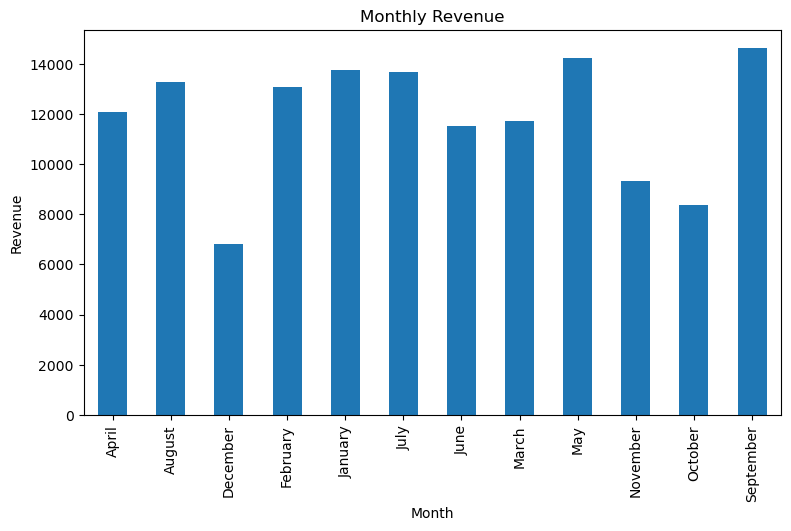

In [36]:
# Monthly Revenue
monthly_sales.plot(kind="bar", figsize=(9, 5), title="Monthly Revenue")

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

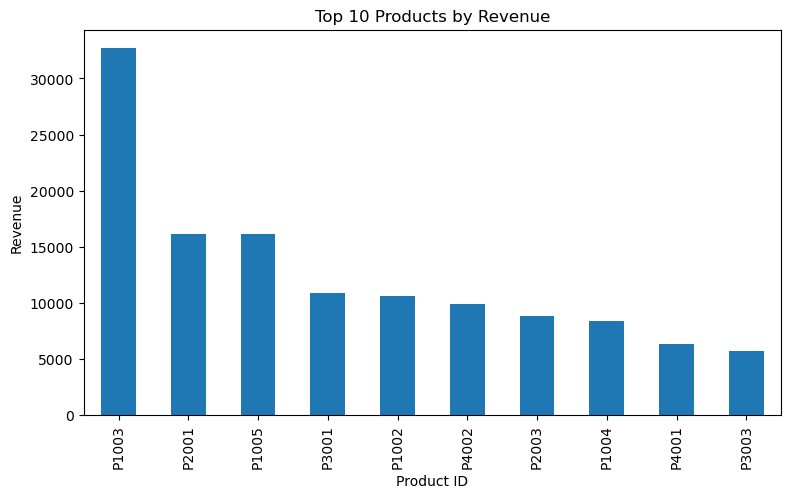

In [23]:
product_sales.head(10).plot(
    kind="bar",
    figsize=(9, 5),
    title="Top 10 Products by Revenue"
)

plt.xlabel("Product ID")
plt.ylabel("Revenue")
plt.show()

In [39]:
orders_clean.to_csv("cleaned_orders.csv", index=False)
customers_clean.to_csv("cleaned_customers.csv", index=False)
products_clean.to_csv("cleaned_products.csv", index=False)

print("All 3 cleaned files saved successfully!")

All 3 cleaned files saved successfully!


In [40]:
import os

for file in ["cleaned_orders.csv", "cleaned_customers.csv", "cleaned_products.csv"]:
    print(file, ":", os.path.exists(file))
    

cleaned_orders.csv : True
cleaned_customers.csv : True
cleaned_products.csv : True
